# Stage 1: SETUP
To begin working on the project, 2 dependencies must be installed due to the nature of the data:

In [1]:
# pip install requirements
!pip install openpyxl pdfplumber -q

In [2]:
!pip install xlrd -q

In [3]:
# Import necessary dependencies
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn
import os
import warnings

In [4]:
BASE  = "/content/drive/MyDrive/cap-and-trade-project/"
RAW   = BASE + "data/raw/"
CLEAN = BASE + "data/clean/"
OUT   = BASE + "output/"

In [5]:
pd.set_option("display.max_columns", None)

# Stage 2: Collect and clean data

After installing the dependencies, we can parse through the raw data from /data/raw and save the cleaned versions into /data/clean

In [6]:
# Suppress harmless styling warnings from openpyxl and xlrd
warnings.filterwarnings("ignore")

raw_dir = Path(RAW)

# Find all .xls and .xlsx files across directories
valid_exts = {".xlsx", ".xls"}
eex_files = sorted(
    [
        p
        for p in raw_dir.rglob("*")
        if p.is_file()
        and p.suffix.lower() in valid_exts
        and not p.name.startswith("~")
    ]
)

all_dfs = []

for filepath in eex_files:
    fname = filepath.name

    try:
        # sheet_name=None loads all sheets into a dictionary
        sheets_dict = pd.read_excel(filepath, sheet_name=None, header=None)
    except Exception as e:
        print(f"Error reading {fname}: {e}")
        continue

    for sheet_name, raw_sheet in sheets_dict.items():
        if raw_sheet.empty or raw_sheet.shape[0] < 5:
            continue

        # Detect the row index containing column names
        header_row_idx = None
        for idx in range(min(12, len(raw_sheet))):
            row_vals = " ".join(
                raw_sheet.iloc[idx].dropna().astype(str)
            ).lower()
            if "date" in row_vals and any(
                w in row_vals
                for w in ["price", "auction", "volume", "settlement", "eua"]
            ):
                header_row_idx = idx
                break

        if header_row_idx is None:
            # Fallback check if only 'date' is present
            for idx in range(min(12, len(raw_sheet))):
                row_vals = " ".join(
                    raw_sheet.iloc[idx].dropna().astype(str)
                ).lower()
                if "date" in row_vals:
                    header_row_idx = idx
                    break

        if header_row_idx is None:
            continue

        # Extract data table
        df = raw_sheet.iloc[header_row_idx + 1 :].copy()
        df.columns = raw_sheet.iloc[header_row_idx]

        # Clean column names
        df.columns = [
            str(c)
            .strip()
            .lower()
            .replace(" ", "_")
            .replace("/", "_")
            .replace("\n", "_")
            for c in df.columns
        ]

        # Identify date column
        date_candidates = [c for c in df.columns if "date" in c]
        if not date_candidates:
            continue
        date_col = date_candidates[0]

        # Parse dates (dayfirst handles European format DD/MM/YYYY)
        df[date_col] = pd.to_datetime(
            df[date_col], dayfirst=True, errors="coerce"
        )
        df = df.dropna(subset=[date_col])

        if not df.empty:
            df["source_file"] = fname
            df["parsed_date"] = df[date_col]
            all_dfs.append(df)

# Concatenate all years
eex_master = pd.concat(all_dfs, ignore_index=True)

# Sort chronologically
eex_master = eex_master.sort_values(by="parsed_date", ascending=True).reset_index(
    drop=True
)

In [7]:
# Saves concatenated .xlsx and .xls files into .csv file
eex_master.to_csv(CLEAN + "eex_master_2012_2026.csv", index=False)

In [8]:
import re
import pdfplumber
pdf_path = RAW + "results_summary.pdf"

all_rows = []
table_settings = {
    "vertical_strategy": "lines",
    "horizontal_strategy": "lines",
}

print("Extracting tables from PDF...")
with pdfplumber.open(pdf_path) as pdf:
    for page in pdf.pages:
        table = page.extract_table(table_settings)
        if not table or len(table) < 2:
            table = page.extract_table()

        if table:
            for r in table:
                if any(str(c).strip() not in ("None", "", "NoneType") for c in r):
                    cleaned = [
                        re.sub(r"\s+", " ", str(c).strip()) if str(c) not in ("None", "") else "" for c in r
                    ]
                    all_rows.append(cleaned)

raw_df = pd.DataFrame(all_rows)
aligned_rows = []
auction_regex = r"auction\s*#?\s*\d+"

# Align the alternating odd/even auction rows
for _, row in raw_df.iterrows():
    col0_val = str(row.iloc[0]).strip() if len(row) > 0 else ""
    col1_val = str(row.iloc[1]).strip() if len(row) > 1 else ""

    if re.search(auction_regex, col0_val, re.IGNORECASE):
        aligned_rows.append(row.values.tolist())
    elif re.search(auction_regex, col1_val, re.IGNORECASE):
        # Shift row left by 1 to align the zig-zag
        shifted_row = row.values.tolist()[1:] + [""]
        aligned_rows.append(shifted_row)

carb_df = pd.DataFrame(aligned_rows)

if carb_df.empty:
    raise ValueError("DataFrame is empty! Check the PDF path and extraction.")

# Hardcoded columns
hardcoded_columns = [
    "auction_name",
    "vintage",
    "current_ca_state_owned_offered",
    "current_ca_consigned_offered",
    "current_qc_offered",
    "current_total_offered",
    "current_ca_state_owned_sold",
    "current_qc_sold",
    "current_total_sold",
    "current_settlement_price_usd",
    "current_settlement_price_cad",
    "advance_ca_state_owned_offered",
    "advance_qc_offered",
    "advance_total_offered",
    "advance_ca_state_owned_sold",
    "advance_qc_sold",
    "advance_total_sold",
    "advance_settlement_price_usd",
    "advance_settlement_price_cad",
    "exchange_rate_usd_cad",
    "total_joint_auction_proceeds_usd",
    "margin_spacer" # Catch-all for extra columns detected by pdfplumber lines
]

carb_df.columns = hardcoded_columns[:carb_df.shape[1]]

# Sort chronologically
carb_df["auction_num"] = (
    carb_df.iloc[:, 0]
    .astype(str)
    .str.extract(r"auction\s*#?\s*(\d+)", flags=re.IGNORECASE)[0]
    .astype(float)
)

# Drop non-auction rows, sort from Auction 1 up to current
carb_df = carb_df.dropna(subset=["auction_num"]).sort_values("auction_num")
carb_df["auction_num"] = carb_df["auction_num"].astype(int)

# Reorder columns to put auction_num first
carb_cols = ["auction_num"] + [c for c in carb_df.columns if c != "auction_num"]
carb_df = carb_df[carb_cols].reset_index(drop=True)

print(f"Successfully processed {len(carb_df)} auctions!")
display(carb_df.head(5))

# Save the final version
carb_df.to_csv(CLEAN + "carb_master_cleaned.csv", index=False)

Extracting tables from PDF...
Successfully processed 56 auctions!


,auction_num,auction_name,vintage,current_ca_state_owned_offered,current_ca_consigned_offered,current_qc_offered,current_total_offered,current_ca_state_owned_sold,current_qc_sold,current_total_sold,current_settlement_price_usd,current_settlement_price_cad,advance_ca_state_owned_offered,advance_qc_offered,advance_total_offered,advance_ca_state_owned_sold,advance_qc_sold,advance_total_sold,advance_settlement_price_usd,advance_settlement_price_cad,exchange_rate_usd_cad,total_joint_auction_proceeds_usd
0,1,November 2012 Auction #1,,,"23,126,110",,,"23,126,110",,,$10.09,,,"39,450,000",,,"5,576,000",,,$10.00,,
1,1,November 2014 Joint Auction #1,,,"23,070,987",,,"23,070,987",,,$12.10,,,"10,787,000",,,"10,787,000",,,$11.86,,
2,2,February 2015 Joint Auction #2,,,"73,610,528",,,"73,610,528",,,$12.21,,,"10,431,500",,,"10,431,500",,,$12.10,,
3,2,February 2013 Auction #2,,,"12,924,822",,,"12,924,822",,,$13.62,,,"9,560,000",,,"4,440,000",,,$10.71,,
4,3,May 2013 Auction #3,,,"14,522,048",,,"14,522,048",,,$14.00,,,"9,560,000",,,"7,515,000",,,$10.71,,


In [9]:
# Load in RGGI data from https link
rggi_all = pd.read_html('https://www.rggi.org/auctions/auction-results/prices-volumes')
rggi_concat = pd.concat(rggi_all, ignore_index=True)
rggi_concat.to_csv(CLEAN + 'rggi_data.csv')

# Stage 3: Combine data together
After loading and cleaning in all the data, we can define our working DataFrames for ease of use

In [10]:
# Defining working DataFrames

# European Energy Exchange data (2012 - 2026)
eex = pd.read_csv(CLEAN + 'eex_master_2012_2026.csv')
# California Air Resources Board data (Individual + Joint data | 2012 - 2026)
carb = pd.read_csv(CLEAN + 'carb_master_cleaned.csv')
# Regional Greenhouse Gas Initiative data (2008 - 2026)
rggi = pd.read_csv(CLEAN + 'rggi_data.csv')
# Table 5 from Dr. Bryan Buckley's PhD Dissertation
bd = pd.read_csv(CLEAN + 'BuckleyPhD.csv')

We want to rename all the columns of the clearing price to a standard column name 'price' to match the "bd" DataFrame. We also want to standardize the dates.

In [11]:
cols = bd.columns

In [12]:
eex_clean = (
    eex
    .rename(columns={"auction_price_€_tco2": "price"})
    .assign(
        date=lambda d: pd.to_datetime(d["date"], format='mixed'),
        year=lambda d: d["date"].dt.year,
        program="EU ETS",
        source="EEX",
        currency="EUR",
        unit="mt",
        is_forecast=False,
    )
    .reindex(columns=cols)
)

In [13]:
carb_clean = (
    carb
    .rename(columns={"current_settlement_price_usd": "price", "auction_name": "date"})
    .assign(
        date=lambda d: pd.to_datetime(
        d["date"].str.extract(r"([A-Za-z]+)\s+(\d{4})").agg(" ".join, axis=1),
        format="%B %Y", errors="coerce"
        ),
        year=lambda d: d["date"].dt.year,
        price=lambda d: pd.to_numeric(
            d["price"].astype(str).str.replace(r"[$,]", "", regex=True), errors="coerce"
        ),
        program="California",
        source="CARB",
        currency="USD",
        unit="mt",
        price_basis="nominal",
        is_forecast=False,
    )
    .reindex(columns=cols)
)

In [14]:
rggi_clean = (
    rggi
    .rename(columns={"Clearing Price": "price", "Date": "date"})
    .assign(
        date=lambda d: pd.to_datetime(d["date"]),
        year=lambda d: d["date"].dt.year,
        program="RGGI",
        source="RGGI Inc.",
        currency="USD",
        unit="st",
        is_forecast=False,
    )
    .reindex(columns=cols)
)

In [15]:
combined = pd.concat(
    [bd, eex_clean, rggi_clean, carb_clean],
    ignore_index=True,
)

In [16]:
combined.drop(columns=['Unnamed: 0'], inplace=True)

In [17]:
combined.to_csv(CLEAN + 'combined.csv')

In [18]:
df = pd.read_csv(CLEAN + 'combined.csv')

In [19]:
df.drop(columns=['Unnamed: 0','Unnamed: 0.1'], inplace=True)

# Stage 4: Convert to 2007 USD / Metric Ton

We will use FRED data from a .csv download through the website for historical CPI and EUR/USD exchange rates

In [20]:
def load_fred(path, name):
  s = pd.read_csv(path)
  s.columns = ['date', name]
  s['date'] = pd.to_datetime(s['date'])
  s[name] = pd.to_numeric(s[name], errors="coerce")
  return s.dropna().sort_values("date")
cpi_monthly = load_fred(RAW + "CPIAUCSL.csv", "cpi")
fx = load_fred(RAW + "DEXUSEU.csv", "usd_per_eur")

cpi_annual = cpi_monthly.groupby(cpi_monthly["date"].dt.year)["cpi"].mean()
print("CPI 2007:", cpi_annual.loc[2007])
print('Earliers CPI year:', cpi_annual.index.min())
print("Latest CPI year:", cpi_annual.index.max())

CPI 2007: 207.34416666666667
Earliers CPI year: 1997
Latest CPI year: 2026


In [21]:
ST_PER_MT = 1.10231  # short tons in one metric ton

def to_2007_usd_per_mt(df, cpi_annual, fx):

    out = df.copy()
    out["date"] = pd.to_datetime(out["date"], errors="coerce")
    is_fc = out["is_forecast"].astype(str).str.lower() == "true"

    forecasts = out[is_fc].copy()
    forecasts["price_2007usd_mt"] = forecasts["price"]

    actual = out[~is_fc].dropna(subset=["date", "price"]).sort_values("date")

    # a. Currency
    actual = pd.merge_asof(actual, fx, on="date", direction="backward")
    actual["price_usd"] = np.where(
        actual["currency"] == "EUR", actual["price"] * actual["usd_per_eur"], actual["price"]
    )

    # b. Units
    actual["price_usd_mt"] = np.where(
        actual["unit"] == "st", actual["price_usd"] * ST_PER_MT, actual["price_usd"]
    )

    # c. Inflation
    actual["cpi_year"] = actual["year"].map(cpi_annual)
    actual["price_2007usd_mt"] = actual["price_usd_mt"] * cpi_annual.loc[2007] / actual["cpi_year"]

    return pd.concat([forecasts, actual], ignore_index=True)

In [22]:
combined["price"] = pd.to_numeric(
    combined["price"].astype(str).str.replace(r"[$,€]", "", regex=True), errors="coerce"
)
combined["year"] = pd.to_numeric(combined["year"], errors="coerce")
combined["is_forecast"] = combined["is_forecast"].astype(str).str.lower() == "true"
combined = combined.dropna(subset=["year", "price"])
combined["year"] = combined["year"].astype(int)

converted = to_2007_usd_per_mt(combined, cpi_annual, fx)

print("Missing converted prices:", converted["price_2007usd_mt"].isna().sum())
print(converted["currency"].value_counts(), converted["unit"].value_counts())
print("CPI 2007:", cpi_annual.loc[2007])

Missing converted prices: 0
currency
EUR      2808
USD       139
2007$      44
Name: count, dtype: int64 unit
mt    2908
st      83
Name: count, dtype: int64
CPI 2007: 207.34416666666667


In [23]:
g_program = converted.groupby(['program','year'])['price_2007usd_mt'].mean().reset_index()

# Stage 5: Data Visualization

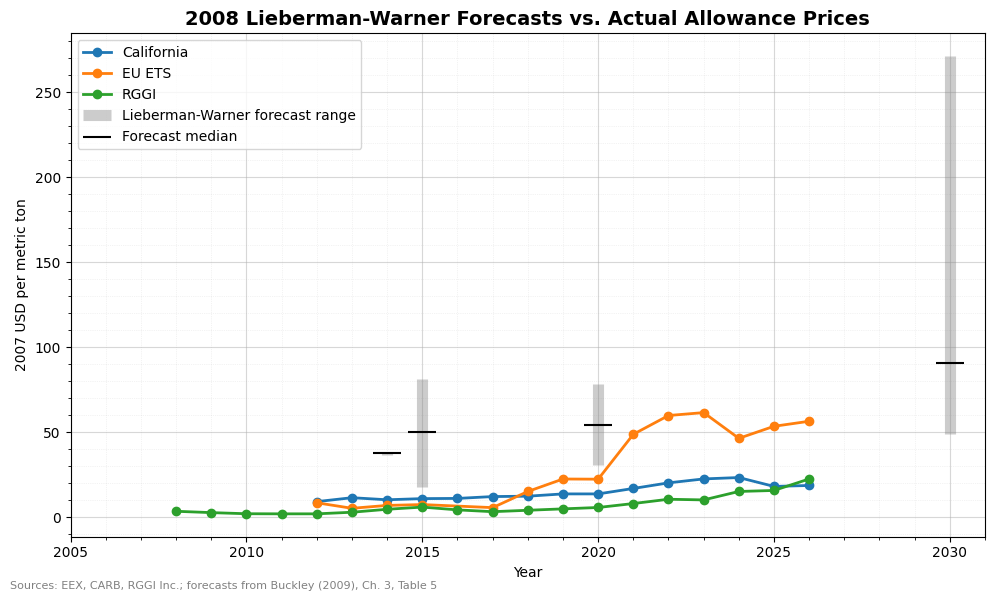

   year    min  median     max
0  2014  36.69  37.525   38.36
1  2015  17.43  50.370   81.13
2  2020  30.84  54.480   78.12
3  2030  49.03  90.830  271.27
program
RGGI          19
California    15
EU ETS        14
Name: count, dtype: int64


In [24]:
from matplotlib.ticker import MultipleLocator
plot_df = converted.copy()

# Clean types
plot_df["price"] = pd.to_numeric(
    plot_df["price"].astype(str).str.replace(r"[$,]", "", regex=True), errors="coerce"
)
plot_df["year"] = pd.to_numeric(plot_df["year"], errors="coerce")
plot_df["is_forecast"] = plot_df["is_forecast"].astype(str).str.lower() == "true"
plot_df = plot_df.dropna(subset=["year", "price"])
plot_df["year"] = plot_df["year"].astype(int)

# Actual prices: one average per program per year
actual_annual = (
    plot_df[~plot_df["is_forecast"]]
    .groupby(["program", "year"], as_index=False)["price_2007usd_mt"]
    .mean()
)

# Forecasts: range and median across all studies at each forecast year
fc = (
    plot_df[plot_df["is_forecast"]]
    .groupby("year")["price_2007usd_mt"]
    .agg(["min", "median", "max"])
    .reset_index()
)
fc = fc[fc["year"] <= 2030]
# --- Plot ---
fig, ax = plt.subplots(figsize=(10, 6))

for program_name in actual_annual["program"].unique():
    p = actual_annual[actual_annual["program"] == program_name]
    ax.plot(p["year"], p["price_2007usd_mt"], marker="o", linewidth=2, label=program_name)

ax.vlines(fc["year"], fc["min"], fc["max"], color="gray", linewidth=8, alpha=0.4,
          label="Lieberman-Warner forecast range")
ax.scatter(fc["year"], fc["median"], color="black", marker="_", s=400, zorder=4,
           label="Forecast median")

ax.set_xlim(2005, 2031)
ax.set_title("2008 Lieberman-Warner Forecasts vs. Actual Allowance Prices",
             fontsize=14, fontweight="bold")
ax.set_xlabel("Year")
ax.set_ylabel("2007 USD per metric ton")
ax.xaxis.set_major_locator(MultipleLocator(5))
ax.yaxis.set_major_locator(MultipleLocator(50))
ax.xaxis.set_minor_locator(MultipleLocator(1))
ax.yaxis.set_minor_locator(MultipleLocator(10))

ax.grid(which="major", linestyle="-", linewidth=0.8, alpha=0.5)
ax.grid(which="minor", linestyle=":", linewidth=0.5, alpha=0.3)

ax.legend(loc="upper left")

fig.text(0.01, 0.01,
         "Sources: EEX, CARB, RGGI Inc.; forecasts from Buckley (2009), Ch. 3, Table 5",
         fontsize=8, color="gray")

plt.tight_layout()
plt.show()

print(fc)
print(actual_annual["program"].value_counts())

# Stage 6: Household Impact Analysis

In [25]:
g_program_rggi = g_program[g_program['program']=='RGGI']
g_program_rggi

,program,year,price_2007usd_mt
34,RGGI,2008,3.424314
35,RGGI,2009,2.639071
36,RGGI,2010,1.979529
37,RGGI,2011,1.920541
38,RGGI,2012,1.921354
39,RGGI,2013,2.864920
40,RGGI,2014,4.612862
41,RGGI,2015,5.889894
42,RGGI,2016,4.254408
43,RGGI,2017,3.188902


In [26]:
g_program_cali = g_program[g_program['program']=='California']
g_program_cali

,program,year,price_2007usd_mt
0,California,2012,9.112498
1,California,2013,11.419642
2,California,2014,10.200126
3,California,2015,10.881114
4,California,2016,10.997632
5,California,2017,12.091925
6,California,2018,12.307730
7,California,2019,13.653838
8,California,2020,13.649087
9,California,2021,16.864626


In [27]:
pop_raw = pd.read_csv(RAW + "Table.csv", dtype={"GeoFIPS": str})

pop = (pop_raw
       .assign(state=lambda d: d["GeoName"].str.replace("*", "", regex=False).str.strip(),
               fips=lambda d: d["GeoFIPS"].str.strip().astype(int))
       .query("0 < fips < 90000")                     # drop US total (0) and BEA regions (91000+)
       .melt(id_vars=["state", "fips"], value_vars=[str(y) for y in range(2000, 2026)],
             var_name="year", value_name="population")
       .assign(year=lambda d: d["year"].astype(int),
               population=lambda d: pd.to_numeric(d["population"], errors="coerce")))

# Membership table
membership = pd.DataFrame([
    *[(s, "RGGI", 2009, 2100) for s in ["Connecticut", "Delaware", "Maine", "Maryland",
       "Massachusetts", "New Hampshire", "New York", "Rhode Island", "Vermont"]],
    ("New Jersey", "RGGI", 2009, 2011),
    ("New Jersey", "RGGI", 2020, 2100),
    ("Virginia",   "RGGI", 2021, 2023),
    ("California", "California", 2013, 2100),
], columns=["state", "program", "start", "end"])

# Flag each state-year with its program
panel = pop.merge(membership, on="state", how="left")
in_program = panel["year"].between(panel["start"], panel["end"])
panel["program"] = panel["program"].where(in_program)
panel = (panel.sort_values("program")
              .drop_duplicates(["state", "year"])
              .drop(columns=["start", "end"]))
panel["group"] = panel["program"].fillna("No program")

# Program population by year
program_pop = (panel.dropna(subset=["program"])
               .groupby(["program", "year"])["population"].sum()
               .rename("pop").reset_index())

# 2007 dollars throughout
price_2007 = (converted[converted["program"].isin(["California", "RGGI"])]
              .groupby(["program", "year"])["price_2007usd_mt"].mean()
              .rename("p_bar").reset_index())



caps = pd.DataFrame({
    "program": ["California", "California", "RGGI", "RGGI"],
    "year":    [2015, 2020, 2015, 2020],
    "cap":     [394500000, 334200000, 66833592, 74283807],  # CA: 17 CCR § 95841; RGGI: adjusted cap, short tons
})
caps["cap_mt"] = np.where(caps["program"] == "RGGI", caps["cap"] / 1.10231, caps["cap"])
burden = (caps.merge(price_2007, on=["program", "year"])
              .merge(program_pop, on=["program", "year"]))
burden["cost_per_person"] = burden["cap_mt"] * burden["p_bar"] / burden["pop"]
burden

,program,year,cap,cap_mt,p_bar,pop,cost_per_person
0,California,2015,394500000,3.945000e+08,10.881114,38966939,110.160038
1,California,2020,334200000,3.342000e+08,13.649087,39527808,115.400399
2,RGGI,2015,66833592,6.063049e+07,5.889894,41953570,8.511961
3,RGGI,2020,74283807,6.738922e+07,5.657524,51610728,7.387148


In [28]:
# Load and reshape BEA PCE per capita by state
pce_raw = pd.read_csv(RAW + "Table_PCE.csv", dtype={"GeoFIPS": str})

pce = (pce_raw
       .assign(state=lambda d: d["GeoName"].str.replace("*", "", regex=False).str.strip(),
               fips=lambda d: d["GeoFIPS"].str.strip().astype(int))
       .melt(id_vars=["state", "fips"], value_vars=[str(y) for y in range(2000, 2026)],
             var_name="year", value_name="pce_pc_nominal")
       .assign(year=lambda d: d["year"].astype(int),
               pce_pc_nominal=lambda d: pd.to_numeric(d["pce_pc_nominal"], errors="coerce")))
pce["pce_pc_2007"] = pce["pce_pc_nominal"] * cpi_annual.loc[2007] / pce["year"].map(cpi_annual)

pce_us = pce[pce["fips"] == 0][["year", "pce_pc_2007"]]          # national line for the chart later
pce_states = pce[(pce["fips"] > 0) & (pce["fips"] < 90000)]

# Add to the state panel
panel = panel.merge(pce_states[["state", "year", "pce_pc_nominal", "pce_pc_2007"]],
                    on=["state", "year"], how="left")

# Program-level PCE per capita, population-weighted
program_pce = (panel.dropna(subset=["program"])
               .assign(pce_total=lambda d: d["pce_pc_2007"] * d["population"])
               .groupby(["program", "year"])[["pce_total", "population"]].sum()
               .assign(pce_pc_2007=lambda d: d["pce_total"] / d["population"])
               [["pce_pc_2007"]].reset_index())

# Burden as a share of consumption
burden = burden.merge(program_pce, on=["program", "year"])
burden["share_of_pce"] = burden["cost_per_person"] / burden["pce_pc_2007"]
burden[["program", "year", "cost_per_person", "pce_pc_2007", "share_of_pce"]]

,program,year,cost_per_person,pce_pc_2007,share_of_pce
0,California,2015,110.160038,35826.532796,0.003075
1,California,2020,115.400399,38272.712225,0.003015
2,RGGI,2015,8.511961,38137.652372,0.000223
3,RGGI,2020,7.387148,38758.672540,0.000191


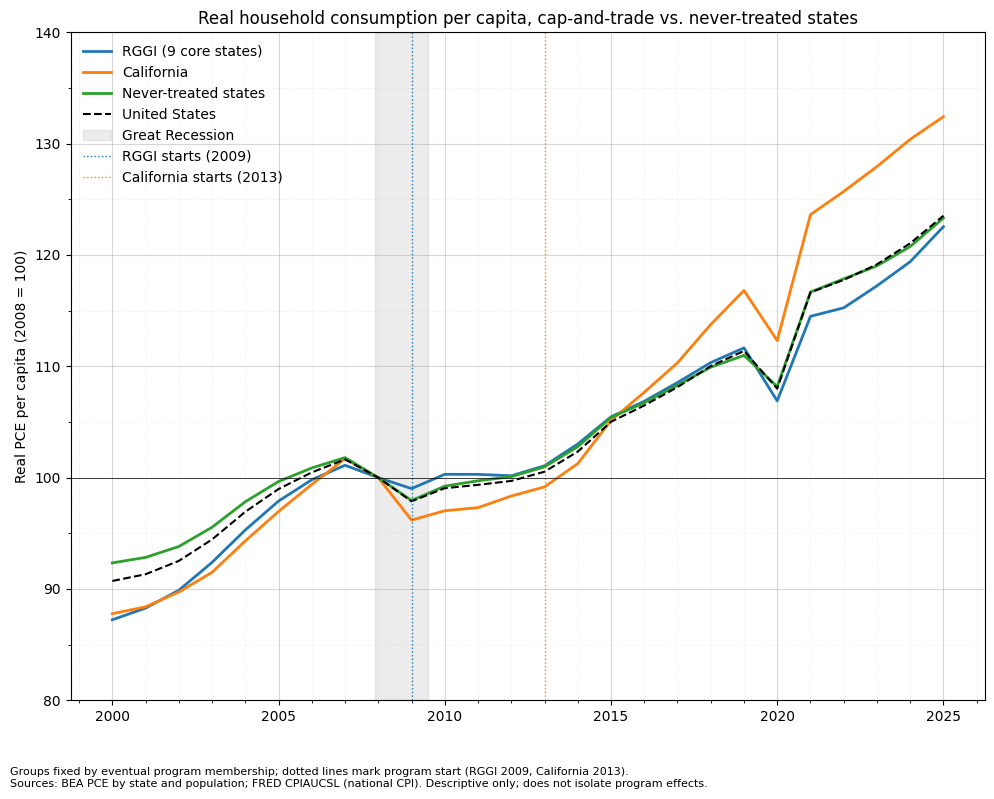

In [29]:
rggi_core = ["Connecticut", "Delaware", "Maine", "Maryland", "Massachusetts",
             "New Hampshire", "New York", "Rhode Island", "Vermont"]
partial = ["New Jersey", "Virginia", "Washington"]

panel["chart_group"] = np.select(
    [panel["state"].isin(rggi_core), panel["state"] == "California", panel["state"].isin(partial)],
    ["RGGI (9 core states)", "California", "Excluded"],
    default="Never-treated states")

# Population-weighted mean real PCE per capita by group and year
grp = (panel[panel["chart_group"] != "Excluded"]
       .assign(w=lambda d: d["pce_pc_2007"] * d["population"])
       .groupby(["chart_group", "year"])[["w", "population"]].sum()
       .assign(pce_pc_2007=lambda d: d["w"] / d["population"])
       ["pce_pc_2007"].unstack("chart_group"))
grp["United States"] = pce_us.set_index("year")["pce_pc_2007"]

# Index to 2008 = 100
idx = grp / grp.loc[2008] * 100

fig, ax = plt.subplots(figsize=(10, 8))
for col in ["RGGI (9 core states)", "California", "Never-treated states"]:
    ax.plot(idx.index, idx[col], label=col, linewidth=2)
ax.plot(idx.index, idx["United States"], label="United States", color="black", linestyle="--")

ax.axvspan(2007.9, 2009.5, color="gray", alpha=0.15, label="Great Recession")
ax.axvline(2009, color="C0", linestyle=":", linewidth=1, label="RGGI starts (2009)")
ax.axvline(2013, color="C1", linestyle=":", linewidth=1, label="California starts (2013)")
ax.axhline(100, color="black", linewidth=0.5)

ax.set_ylabel("Real PCE per capita (2008 = 100)")
ax.set_title("Real household consumption per capita, cap-and-trade vs. never-treated states")
ax.set_ylim(80,140)
ax.xaxis.set_major_locator(MultipleLocator(5))
ax.yaxis.set_major_locator(MultipleLocator(10))
ax.xaxis.set_minor_locator(MultipleLocator(1))
ax.yaxis.set_minor_locator(MultipleLocator(5))

ax.grid(which="major", linestyle="-", linewidth=0.8, alpha=0.5)
ax.grid(which="minor", linestyle=":", linewidth=0.5, alpha=0.3)

ax.legend(frameon=False)
fig.text(0.01, 0.01, "Groups fixed by eventual program membership; dotted lines mark program start "
         "(RGGI 2009, California 2013).\nSources: BEA PCE by state and population; FRED CPIAUCSL "
         "(national CPI). Descriptive only; does not isolate program effects.", fontsize=8)
plt.tight_layout(rect=[0, 0.07, 1, 1])

In [30]:
def mde(grp, treated_col, start, control_col="Never-treated states", end=2025):
    gap = np.log(grp[treated_col]) - np.log(grp[control_col])      # log level gap
    pre = gap.loc[:start - 1].dropna()

    slope, intercept = np.polyfit(pre.index, pre.values, 1)
    resid_sd = (pre - (slope * pre.index + intercept)).std(ddof=2)

    n_pre, n_post = len(pre), len(gap.loc[start:end].dropna())
    return {"program": treated_col, "resid_sd": resid_sd, "n_pre": n_pre, "n_post": n_post,
            "mde": 2.8 * resid_sd * np.sqrt((1 / n_pre) + (1 / n_post))} # 5% significance level and 80% power

mde_table = pd.DataFrame([
    mde(grp, "RGGI (9 core states)", 2009),
    mde(grp, "California", 2013),
])
mde_table["expected"] = [0.0002, 0.003]
mde_table["detectable"] = mde_table["expected"] >= mde_table["mde"]
mde_table

,program,resid_sd,n_pre,n_post,mde,expected,detectable
0,RGGI (9 core states),0.001659,9,17,0.001915,0.0002,False
1,California,0.012006,13,13,0.013185,0.0030,False


In [31]:
converted.to_csv(CLEAN + "prices_converted.csv", index=False)
cpi_annual.to_csv(CLEAN + "cpi_annual.csv")
membership.to_csv(CLEAN + "membership.csv", index=False)
panel.to_csv(CLEAN + "state_panel.csv", index=False)